# **Traffic Volume Prediction using Machine Learning**

In this project, we work with a dataset containing traffic counts for four different vehicle types: cars, bikes, buses, and trucks. The data is recorded at 15-minute intervals over a period of two months.

The main objective is to develop machine learning models capable of predicting the traffic volume for each vehicle category. Since our target variables represent numerical quantities, this task can be formulated as a **regression** problem.

To tackle this task, we apply two widely used ensemble learning algorithms: **XGBoost** and **Random Forest**. Both methods are well-established approaches for regression tasks and are capable of capturing complex, non-linear relationships within the data.

We will train and evaluate both models, compare their predictive performance, and investigate how accurately they can forecast traffic volumes across the four vehicle categories.

Lets get started!

## **1. Load the Dataset**

In [1]:
from google.colab import files

uploaded = files.upload()

Saving TrafficTwoMonth.csv to TrafficTwoMonth.csv


In [2]:
import pandas as pd
import numpy as np

# Read the Data
df = pd.read_csv("TrafficTwoMonth.csv")

## **2. Initial Exploratory Data Analysis (EDA)**

The first step is to perform an initial exploratory data analysis (EDA) to gain a general understanding of the dataset. We examine its dimensions, structure, and data types to identify the variables and assess the overall quality of the data.

In [3]:
# Get 10 rows of insight of the data
df.head(10)

,Time,Date,Day of the week,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation
0,12:00:00 AM,10,Tuesday,13,2,2,24,41,normal
1,12:15:00 AM,10,Tuesday,14,1,1,36,52,normal
2,12:30:00 AM,10,Tuesday,10,2,2,32,46,normal
3,12:45:00 AM,10,Tuesday,10,2,2,36,50,normal
4,1:00:00 AM,10,Tuesday,11,2,1,34,48,normal
5,1:15:00 AM,10,Tuesday,15,1,1,39,56,normal
6,1:30:00 AM,10,Tuesday,14,2,2,27,45,normal
7,1:45:00 AM,10,Tuesday,13,2,1,20,36,normal
8,2:00:00 AM,10,Tuesday,7,0,0,26,33,normal
9,2:15:00 AM,10,Tuesday,13,0,0,34,47,normal


In [4]:
# Get insights about the datatypes of the columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5952 entries, 0 to 5951
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Time               5952 non-null   object
 1   Date               5952 non-null   int64 
 2   Day of the week    5952 non-null   object
 3   CarCount           5952 non-null   int64 
 4   BikeCount          5952 non-null   int64 
 5   BusCount           5952 non-null   int64 
 6   TruckCount         5952 non-null   int64 
 7   Total              5952 non-null   int64 
 8   Traffic Situation  5952 non-null   object
dtypes: int64(6), object(3)
memory usage: 418.6+ KB


In [5]:
# Get the shape of the Dataset
df.shape

(5952, 9)

### **Results and Discussion**

The initial inspection shows that the dataset is generally well-structured. We can see that the time values are currently represented in the 12-hour AM/PM format, which we will convert to the 24-hour format in the next preprocessing step.

Furthermore, the data types appear to be correctly assigned. The dataset consists of **5,952 rows** and **9 columns**, providing a solid basis for our subsequent analysis.

## **3. Data Preprocessing**

In this step, we continue by checking the dataset for missing or null values. As discussed in the previous section, we also convert the time values from the 12-hour AM/PM format to the 24-hour format.



In [6]:
# Check for null values
print(df.isnull().sum())

Time                 0
Date                 0
Day of the week      0
CarCount             0
BikeCount            0
BusCount             0
TruckCount           0
Total                0
Traffic Situation    0
dtype: int64


In [7]:
# Check for missing values
print(df.isnull().values.any())

False


In [8]:
# Change the 12 hours time format to 24 hours time format

df["Time"] = pd.to_datetime(df["Time"], format="%I:%M:%S %p").dt.strftime("%H:%M")

df.head(20)

,Time,Date,Day of the week,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation
0,00:00,10,Tuesday,13,2,2,24,41,normal
1,00:15,10,Tuesday,14,1,1,36,52,normal
2,00:30,10,Tuesday,10,2,2,32,46,normal
3,00:45,10,Tuesday,10,2,2,36,50,normal
4,01:00,10,Tuesday,11,2,1,34,48,normal
5,01:15,10,Tuesday,15,1,1,39,56,normal
6,01:30,10,Tuesday,14,2,2,27,45,normal
7,01:45,10,Tuesday,13,2,1,20,36,normal
8,02:00,10,Tuesday,7,0,0,26,33,normal
9,02:15,10,Tuesday,13,0,0,34,47,normal


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5952 entries, 0 to 5951
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Time               5952 non-null   object
 1   Date               5952 non-null   int64 
 2   Day of the week    5952 non-null   object
 3   CarCount           5952 non-null   int64 
 4   BikeCount          5952 non-null   int64 
 5   BusCount           5952 non-null   int64 
 6   TruckCount         5952 non-null   int64 
 7   Total              5952 non-null   int64 
 8   Traffic Situation  5952 non-null   object
dtypes: int64(6), object(3)
memory usage: 418.6+ KB


#### **Results and discussion**

The results show that the dataset contains no missing or null values. Furthermore, we successfully converted the time values from the 12-hour AM/PM format to the 24-hour format.

## **4. Exploratory Data Analysis (EDA)**

In this step, we aim to visualize the traffic data to gain a better understanding of its distribution and patterns. We first examine the total traffic volume and then analyze each vehicle category individually.

#### **Traffic Analysis**

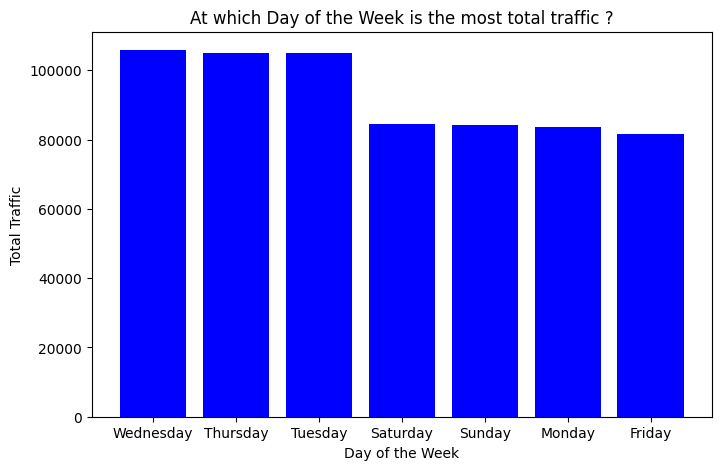

In [10]:
import matplotlib.pyplot as plt

# On which Day of the Week is the most total traffic ?

total = df.groupby("Day of the week")["Total"].sum()
total = total.sort_values(ascending=False)
total.head(10)


weekday = total.index
totals = total.values

plt.figure(figsize=(8, 5))
plt.bar(weekday, totals, color="blue")
plt.title("At which Day of the Week is the most total traffic ?")
plt.xlabel("Day of the Week")
plt.ylabel("Total Traffic")
plt.show()

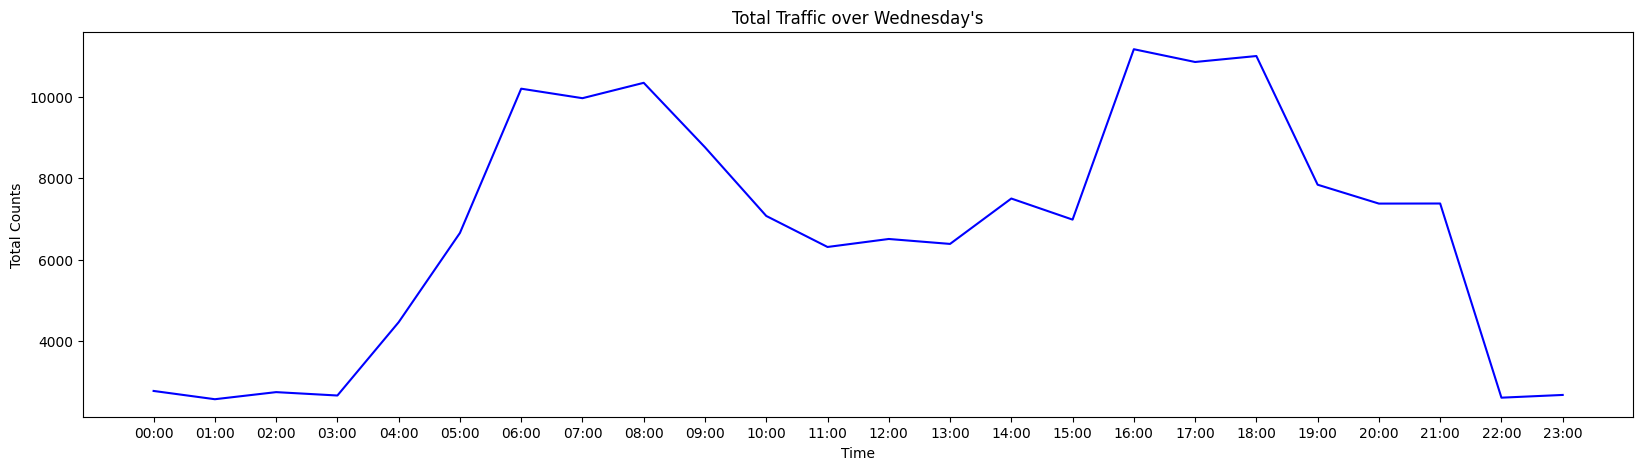

In [11]:
# At which time is the most traffic at the busiest day ?

times = df[df["Day of the week"] == "Wednesday"]
times = df.groupby("Time")["Total"].sum()

# Get full times in "##:00"
times = times.iloc[::4]

time = times.index
totals = times.values



plt.figure(figsize=(20, 5))
plt.plot(time, totals, color="blue")
plt.title("Total Traffic over Wednesday's")
plt.xlabel("Time")
plt.ylabel("Total Counts")
plt.show()

#### **Vehicle Analysis**

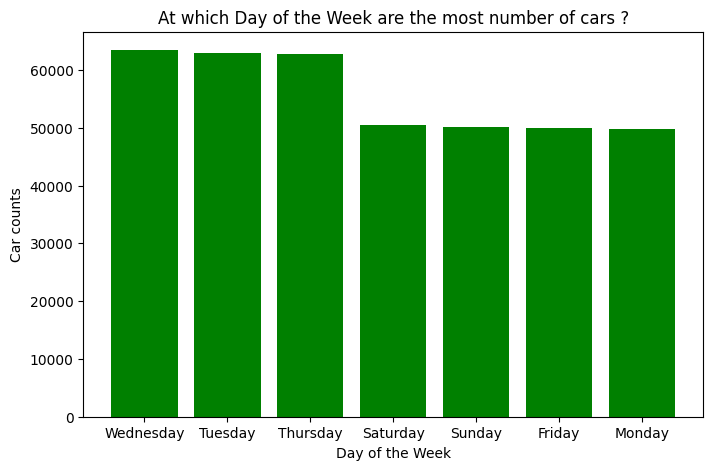

In [12]:
# On which Day of the week is the most car traffic ?

car = df.groupby("Day of the week")["CarCount"].sum()
car = car.sort_values(ascending=False)

weekday = car.index
car_count = car.values

plt.figure(figsize=(8, 5))

plt.bar(weekday, car_count, color="green")
plt.title("At which Day of the Week are the most number of cars ?")
plt.xlabel("Day of the Week")
plt.ylabel("Car counts")
plt.show()

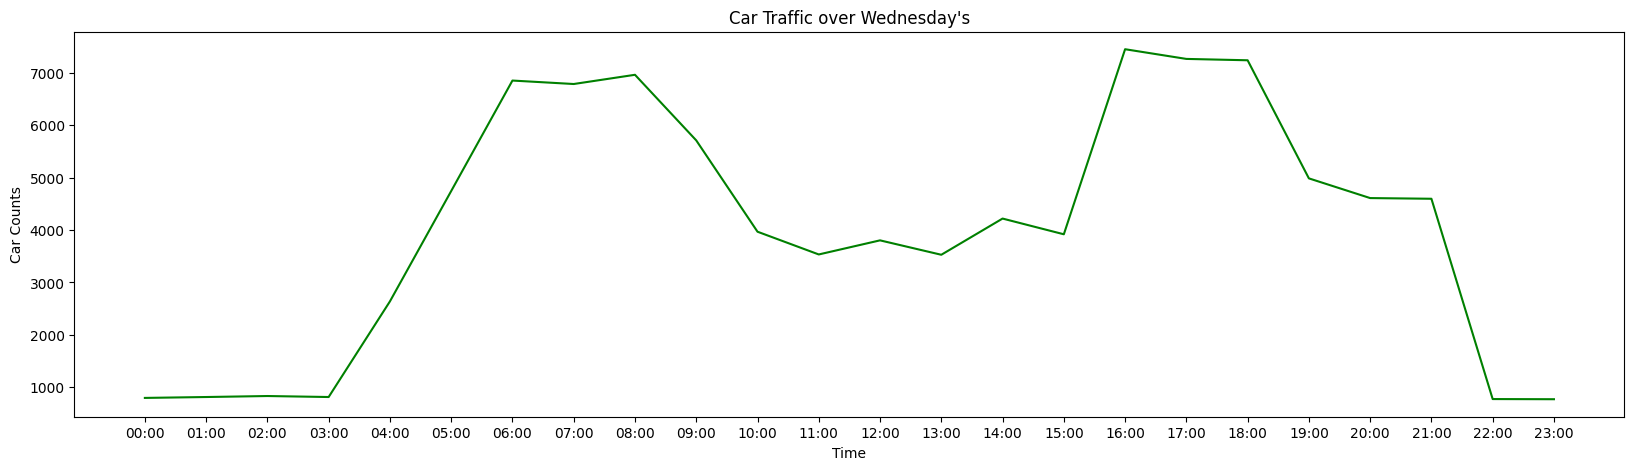

In [13]:
# At which time is the most traffic at the busiest day ?

times = df[df["Day of the week"] == "Wednesday"]
times = df.groupby("Time")["CarCount"].sum()

# Get full times in "##:00"
times = times.iloc[::4]

time = times.index
car_counts = times.values



plt.figure(figsize=(20, 5))
plt.plot(time, car_counts, color="green")
plt.title("Car Traffic over Wednesday's")
plt.xlabel("Time")
plt.ylabel("Car Counts")
plt.show()

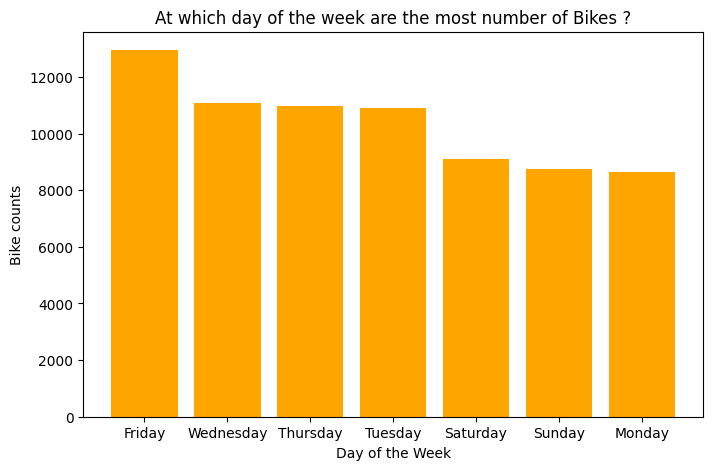

In [14]:
# On which Day of the week is the most bike traffic ?

bike = df.groupby("Day of the week")["BikeCount"].sum()
bike = bike.sort_values(ascending=False)

weekday = bike.index
bike_count = bike.values

plt.figure(figsize=(8, 5))
plt.bar(weekday, bike_count, color="orange")
plt.title("At which day of the week are the most number of Bikes ?")
plt.xlabel("Day of the Week")
plt.ylabel("Bike counts")
plt.show()

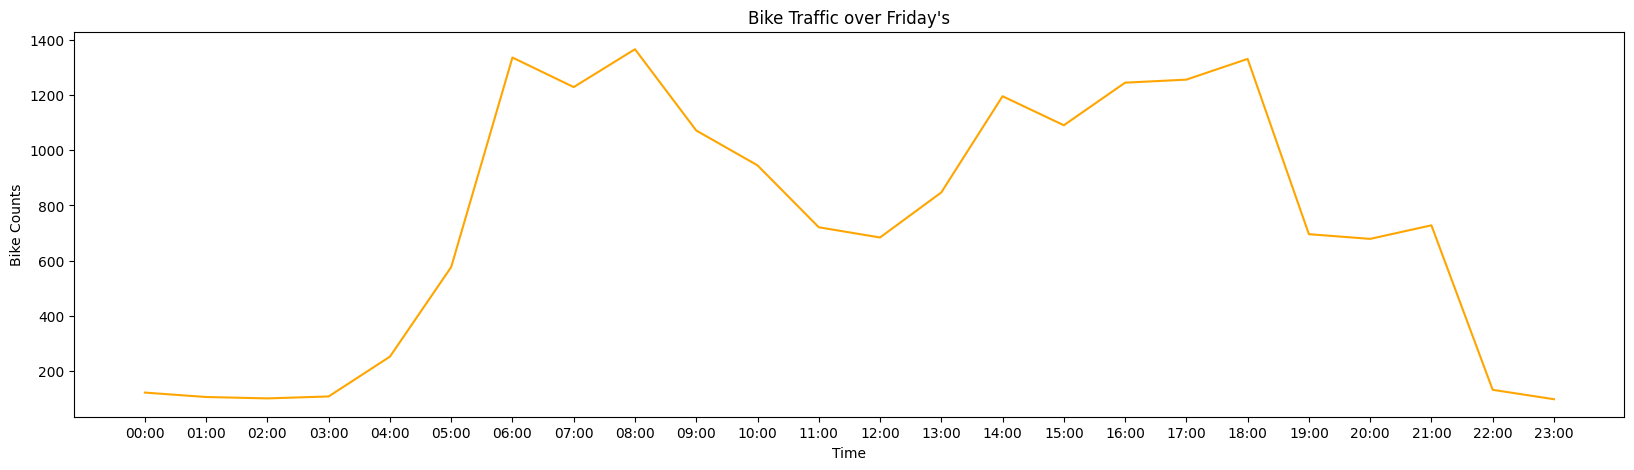

In [15]:
# At which time is the most traffic at the busiest day ?

times = df[df["Day of the week"] == "Friday"]
times = df.groupby("Time")["BikeCount"].sum()

# Get full times in "##:00"
times = times.iloc[::4]

time = times.index
bike_counts = times.values



plt.figure(figsize=(20, 5))
plt.plot(time, bike_counts, color="orange")
plt.title("Bike Traffic over Friday's")
plt.xlabel("Time")
plt.ylabel("Bike Counts")
plt.show()

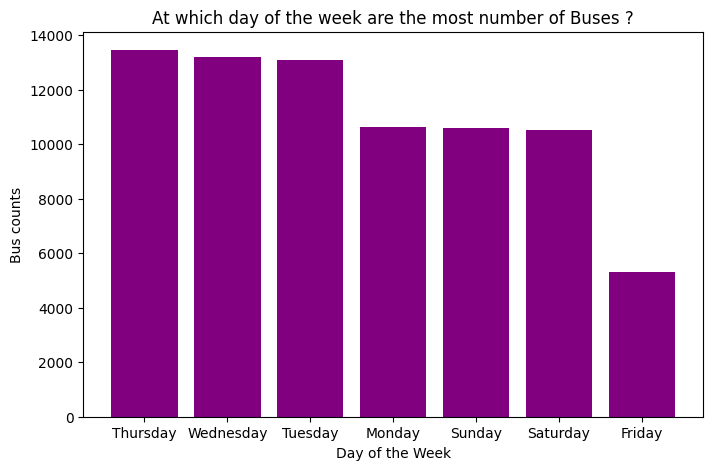

In [16]:
# On which Day of the week is the most bus traffic ?

bus = df.groupby("Day of the week")["BusCount"].sum()
bus = bus.sort_values(ascending=False)

weekday = bus.index
bus_count = bus.values

plt.figure(figsize=(8, 5))
plt.bar(weekday, bus_count, color="purple")
plt.title("At which day of the week are the most number of Buses ?")
plt.xlabel("Day of the Week")
plt.ylabel("Bus counts")
plt.show()

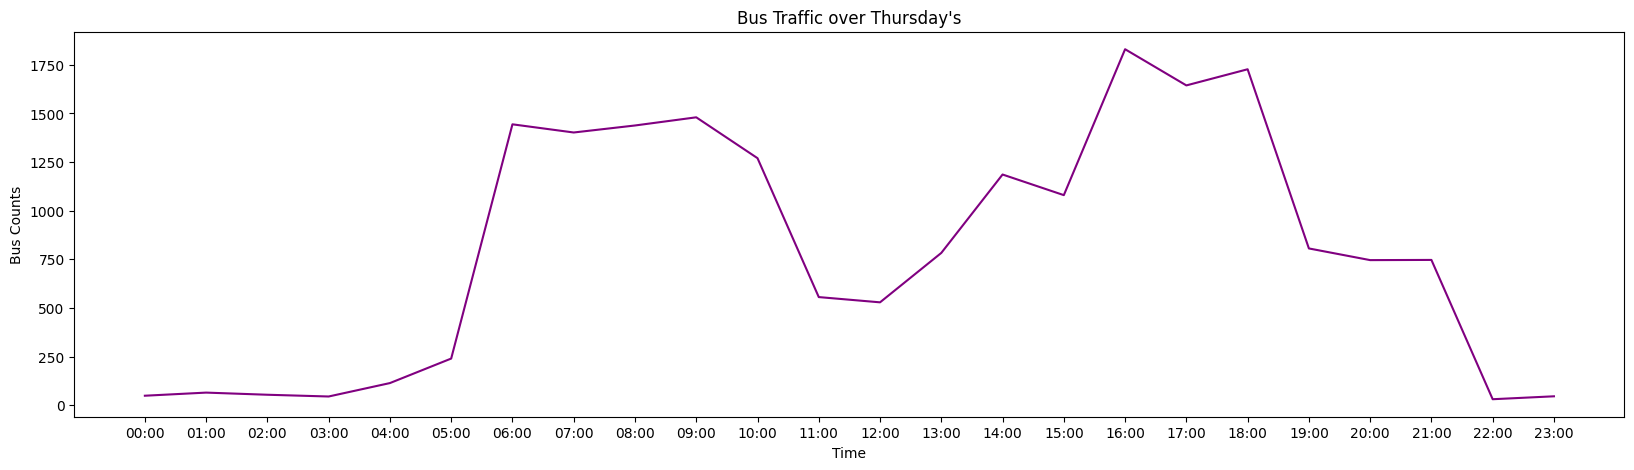

In [17]:
# At which time is the most traffic at the busiest day ?

times = df[df["Day of the week"] == "Thursday"]
times = df.groupby("Time")["BusCount"].sum()

# Get full times in "##:00"
times = times.iloc[::4]

time = times.index
bus_counts = times.values



plt.figure(figsize=(20, 5))
plt.plot(time, bus_counts, color="purple")
plt.title("Bus Traffic over Thursday's")
plt.xlabel("Time")
plt.ylabel("Bus Counts")
plt.show()

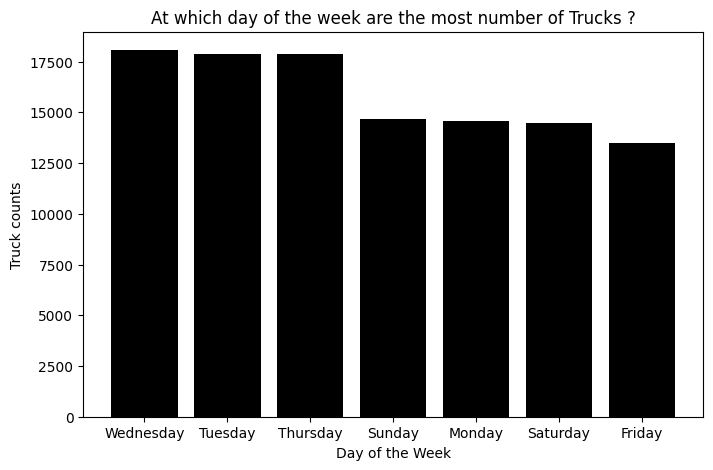

In [18]:
# On which Day of the week is the most truck traffic ?

truck = df.groupby("Day of the week")["TruckCount"].sum()
truck = truck.sort_values(ascending=False)

weekday = truck.index
truck_count = truck.values

plt.figure(figsize=(8, 5))
plt.bar(weekday, truck_count, color="black")
plt.title("At which day of the week are the most number of Trucks ?")
plt.xlabel("Day of the Week")
plt.ylabel("Truck counts")
plt.show()

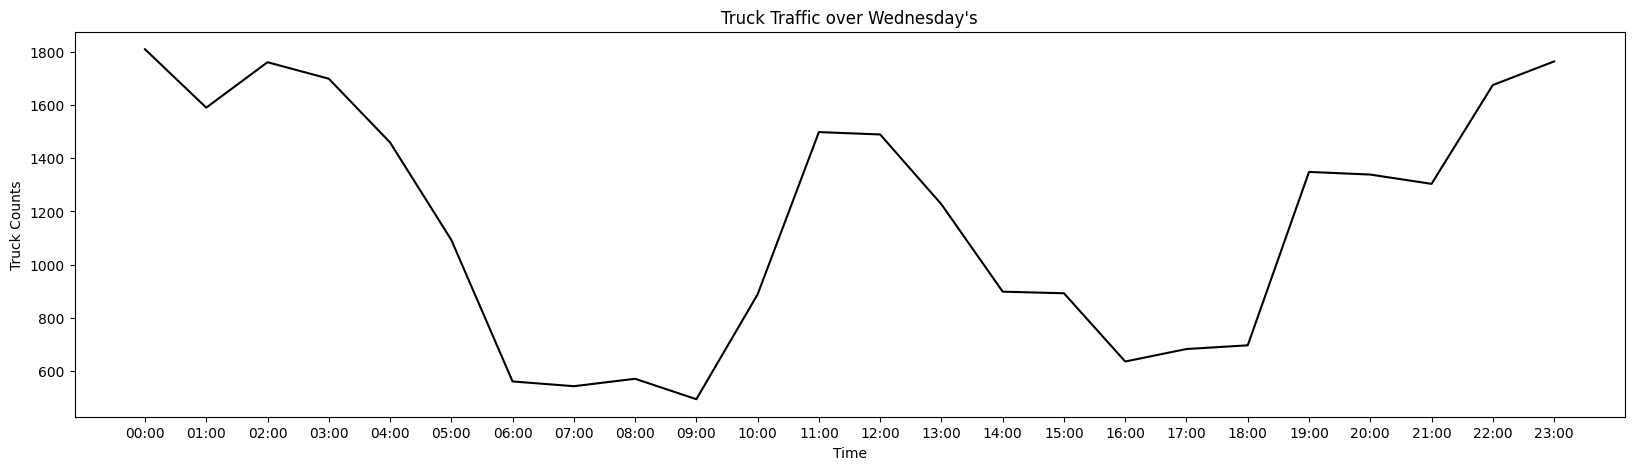

In [19]:
# At which time is the most traffic at the busiest day ?

times = df[df["Day of the week"] == "Wednesday"]
times = df.groupby("Time")["TruckCount"].sum()

# Get full times in "##:00"
times = times.iloc[::4]

time = times.index
truck_counts = times.values



plt.figure(figsize=(20, 5))
plt.plot(time, truck_counts, color="black")
plt.title("Truck Traffic over Wednesday's")
plt.xlabel("Time")
plt.ylabel("Truck Counts")
plt.show()

#### **Results and Discussion**

The visualization shows that total traffic volume is highest on Wednesdays. However, the traffic patterns differ between the individual vehicle categories. Truck traffic is more pronounced at night and around midday. Bus traffic shows peaks in the morning and during the evening rush hour. Bike and car traffic follow somewhat similar patterns to bus traffic. Furthermore, traffic volume across all four vehicle categories is generally higher on weekdays than on weekends.

## **5. Feature Engineering**

In this step, we create a new datetime column named Timestamp by combining the provided date and time values. Since the original year and month are not available in the dataset, we use assumed values to construct the timestamps.

Based on this new column, we generate cyclical features for the hour of the day and the day of the week to capture recurring temporal patterns. Additionally, we create binary features to indicate whether a given day is a weekend, Monday, or Friday, as traffic volume may vary depending on the day of the week.

We also define the target variables using the traffic counts for each vehicle category (cars, bikes, buses, and trucks).

After that we split the dataset chronologically into training, validation, and test sets. We use 70% of the data for training and divide the remaining 30% equally between validation and testing (15% each).

Finally, we apply one-hot encoding to categorical features, such as Traffic Situation, to make them suitable for the machine learning models.


In [20]:
# Create a Timestamp by combining the given dates and times with an assumed year and month, since the original year and month are not available

start_date = pd.Timestamp("2023-10-10")


df["Timestamp"] = pd.date_range(
    start=start_date,
    periods=len(df),
    freq="15min"
)

print(df[["Date", "Time", "Timestamp"]].head())
print(df[["Date", "Time", "Timestamp"]].tail())


   Date   Time           Timestamp
0    10  00:00 2023-10-10 00:00:00
1    10  00:15 2023-10-10 00:15:00
2    10  00:30 2023-10-10 00:30:00
3    10  00:45 2023-10-10 00:45:00
4    10  01:00 2023-10-10 01:00:00
      Date   Time           Timestamp
5947     9  22:45 2023-12-10 22:45:00
5948     9  23:00 2023-12-10 23:00:00
5949     9  23:15 2023-12-10 23:15:00
5950     9  23:30 2023-12-10 23:30:00
5951     9  23:45 2023-12-10 23:45:00


In [21]:

# Create cyclical features for machine learning model

minutes_of_day = (df["Timestamp"].dt.hour * 60 + df["Timestamp"].dt.minute)


df["Hour_sin"] = np.sin(2 * np.pi * minutes_of_day / 1440)
df["Hour_cos"] = np.cos(2 * np.pi * minutes_of_day / 1440)

weekday = df["Timestamp"].dt.dayofweek

df["Weekday_sin"] = np.sin(2 * np.pi * weekday / 7)
df["Weekday_cos"] = np.cos(2 * np.pi * weekday / 7)


# Create features for specific days on which traffic might be different

df["Is_weekend"] = df["Day of the week"].isin(["Saturday", "Sunday"]).astype(int)
df["Is_monday"] = df["Day of the week"].isin(["Monday"]).astype(int)
df["Is_friday"] = df["Day of the week"].isin(["Friday"]).astype(int)

df = df.drop(columns=["Time", "Date", "Day of the week"])
df.insert(0, "Timestamp", df.pop("Timestamp"))

df.head()

,Timestamp,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation,Hour_sin,Hour_cos,Weekday_sin,Weekday_cos,Is_weekend,Is_monday,Is_friday
0,2023-10-10 00:00:00,13,2,2,24,41,normal,0.000000,1.000000,0.781831,0.62349,0,0,0
1,2023-10-10 00:15:00,14,1,1,36,52,normal,0.065403,0.997859,0.781831,0.62349,0,0,0
2,2023-10-10 00:30:00,10,2,2,32,46,normal,0.130526,0.991445,0.781831,0.62349,0,0,0
3,2023-10-10 00:45:00,10,2,2,36,50,normal,0.195090,0.980785,0.781831,0.62349,0,0,0
4,2023-10-10 01:00:00,11,2,1,34,48,normal,0.258819,0.965926,0.781831,0.62349,0,0,0


In [22]:
# Features
X = df.drop(["Timestamp", "CarCount", "BikeCount", "BusCount", "TruckCount", "Total"], axis=1)
X.head()

,Traffic Situation,Hour_sin,Hour_cos,Weekday_sin,Weekday_cos,Is_weekend,Is_monday,Is_friday
0,normal,0.000000,1.000000,0.781831,0.62349,0,0,0
1,normal,0.065403,0.997859,0.781831,0.62349,0,0,0
2,normal,0.130526,0.991445,0.781831,0.62349,0,0,0
3,normal,0.195090,0.980785,0.781831,0.62349,0,0,0
4,normal,0.258819,0.965926,0.781831,0.62349,0,0,0


In [23]:
# Targets
Y = df.iloc[:, 1:5]
Y.head()

,CarCount,BikeCount,BusCount,TruckCount
0,13,2,2,24
1,14,1,1,36
2,10,2,2,32
3,10,2,2,36
4,11,2,1,34


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer


numerical_features = [
                      "Is_weekend",
                      "Is_monday",
                      "Is_friday"
                     ]

cyclical_features = [
          "Hour_sin",
          "Hour_cos",
          "Weekday_sin",
          "Weekday_cos"
          ]

categorical_features = ["Traffic Situation"]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("num", "passthrough", numerical_features),
    ("cyc", "passthrough", cyclical_features)
])


# Split the dataset into training (70%), validation (15%), and test(15%) sets

train_size = int(len(df) * 0.7)
val_size = len(df) - int(len(df) * 0.15)

X_train = X[:train_size]
X_val = X[train_size:val_size]
X_test = X[val_size:]

Y_train = Y[:train_size]
Y_val = Y[train_size:val_size]
Y_test = Y[val_size:]

# Apply one-hot encoding to convert categorical features into numerical
X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)

# Shapes of train, validation, and test sets
print("Shape of X Train Set: ", X_train.shape)
print("Shape of X Test Set: ", X_test.shape)
print("Shape of X Validation Set: ", X_val.shape)
print("Shape of Y Train Set: ", Y_train.shape)
print("Shape of Y Test Set: ", Y_test.shape)
print("Shape of Y Validation Set: ", Y_val.shape)


Shape of X Train Set:  (4166, 11)
Shape of X Test Set:  (892, 11)
Shape of X Validation Set:  (894, 11)
Shape of Y Train Set:  (4166, 4)
Shape of Y Test Set:  (892, 4)
Shape of Y Validation Set:  (894, 4)


## **6. XGBoost Model**

In this step, we initialize an XGBoost model for multi-output regression to predict the traffic counts of all four vehicle categories. To improve the model's predictive performance, we use **RandomizedSearchCV** to find an optimal combination of hyperparameters. We test 50 randomly selected parameter combinations using 5-fold cross-validation and select the model with the lowest mean squared error.

In [25]:
from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



param_grid = [{
    "estimator__n_estimators": [100, 200, 300, 500],
    "estimator__learning_rate": [0.001, 0.01, 0.1, 0.2],
    "estimator__max_depth": [2, 5, 10, 20, 50],
    "estimator__min_child_weight": [1, 3, 5],
    "estimator__reg_lambda": [0.001, 0.01, 0.1]
}]

# Wrap XGBoost in MultiOutputRegressor to support multi-output regression
xgb_model = MultiOutputRegressor(
    XGBRegressor(random_state = 42)
    )

# Randomized search for the best parameters
grid_search = RandomizedSearchCV(xgb_model, param_grid, cv=5, scoring="neg_mean_squared_error", n_iter=50, n_jobs=2, verbose=2)

grid_search.fit(X_train, Y_train)

# Retrieve the best XGBoost model with the optimized hyperparameters
xgb_model = grid_search.best_estimator_


print("Best parameters: ", grid_search.best_params_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters:  {'estimator__reg_lambda': 0.001, 'estimator__n_estimators': 100, 'estimator__min_child_weight': 5, 'estimator__max_depth': 5, 'estimator__learning_rate': 0.2}


## **7. Random Forest Model**

In this step, we initialize a Random Forest model for multi-output regression. Unlike XGBoost, Random Forest supports multiple target variables natively, so no additional wrapper is required. We use **RandomizedSearchCV** to optimize the model's hyperparameters by testing 50 randomly selected parameter combinations with 5-fold cross-validation. Finally, we select the model with the best cross-validation performance based on the mean squared error.

In [26]:
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [2, 5, 10, 20, 50],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 1.0]
}

# Random Forest supports multi-output regression natively
rf_model = RandomForestRegressor(random_state=42)

# Randomized search for the best parameters
grid_search = RandomizedSearchCV(rf_model, param_grid, cv=5, scoring="neg_mean_squared_error", n_iter=50, n_jobs=2, verbose=2)

grid_search.fit(X_train, Y_train)

# Retrieve the best Random Forest model with the optimized hyperparameters
rf_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best parameters: {'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 10}


## **8. XGBoost vs. Random Forest on Validation Set**

In this step, we evaluate both models on the validation set and compare their predictive performance. We first examine the overall model performance, followed by a detailed evaluation of each target variable using individual performance metrics. Finally, we visualize the actual versus predicted traffic counts to assess how accurately the models capture the observed traffic patterns.

#### **Overall Model Performance: XGBoost vs. Random Forest**

In [27]:
# Generate predictions on the validation set for both models
xgb_pred = xgb_model.predict(X_val)
rf_pred = rf_model.predict(X_val)

# Calculate and store evaluation metrics (R², MSE, RMSE, MAE) for both models in a DataFrame
results_val = pd.DataFrame({
    "Model": ["XGBoost", "Random Forest"],
    "R2": [r2_score(Y_val, xgb_pred), r2_score(Y_val, rf_pred)],
    "MSE": [mean_squared_error(Y_val, xgb_pred), mean_squared_error(Y_val, rf_pred)],
    "RMSE": [np.sqrt(mean_squared_error(Y_val, xgb_pred)), np.sqrt(mean_squared_error(Y_val, rf_pred))],
    "MAE": [mean_absolute_error(Y_val, xgb_pred), mean_absolute_error(Y_val, rf_pred)]
})

# Display the validation results rounded to three decimal places
print(results_val.round(3))

           Model     R2      MSE    RMSE    MAE
0        XGBoost  0.772  104.708  10.233  6.623
1  Random Forest  0.770  100.363  10.018  6.601


#### **Metrics per Target: XGBoost vs. Random Forest**

In [28]:
target_names = ["Car Counts", "Bike Counts", "Bus Counts", "Truck Counts"]

# Calculate and compare R² scores for each target variable

results_per_target_val = []

for i, target in enumerate(target_names):

  results_per_target_val.append({
      "Target": target,
      "XGBoost R2": r2_score(Y_val.iloc[:, i], xgb_pred[:, i]),
      "XGBoost RMSE": np.sqrt(mean_squared_error(Y_val.iloc[:, i], xgb_pred[:, i])),
      "XGBoost MAE": mean_absolute_error(Y_val.iloc[:, i], xgb_pred[:, i]),
      "Random Forest R2": r2_score(Y_val.iloc[:, i], rf_pred[:, i]),
      "Random Forest RMSE": np.sqrt(mean_squared_error(Y_val.iloc[:, i], rf_pred[:, i])),
      "Random Forest MAE": mean_absolute_error(Y_val.iloc[:, i], rf_pred[:, i])
  })

# Store the per-target results in a DataFrame
target_comparison_val = pd.DataFrame(results_per_target_val)

# Display the validation results rounded to three decimal places
print(target_comparison_val.round(3))

         Target  XGBoost R2  XGBoost RMSE  XGBoost MAE  Random Forest R2  \
0    Car Counts       0.849        17.438       12.931             0.859   
1   Bike Counts       0.707         6.662        5.003             0.681   
2    Bus Counts       0.805         6.239        4.300             0.807   
3  Truck Counts       0.725         5.608        4.259             0.733   

   Random Forest RMSE  Random Forest MAE  
0              16.857             12.732  
1               6.950              5.172  
2               6.201              4.256  
3               5.527              4.244  


#### **XGBoost - Actual vs. Prediction on Validation Set**

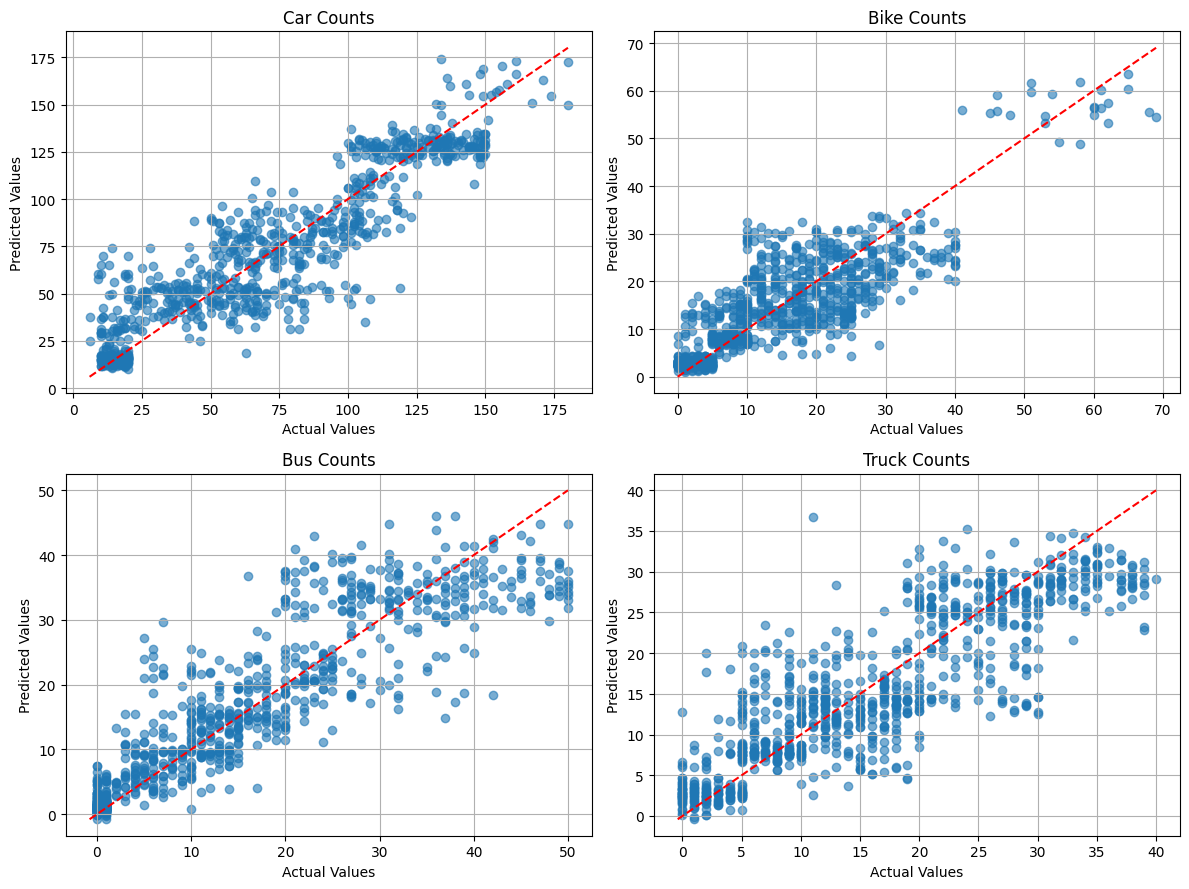

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))


for i, ax in enumerate(axes.flat):

    ax.scatter(Y_val.iloc[:, i], xgb_pred[:, i], alpha=0.6)


    min_val = min(Y_val.iloc[:, i].min(), xgb_pred[:, i].min())
    max_val = max(Y_val.iloc[:, i].max(), xgb_pred[:, i].max())

    ax.plot([min_val, max_val], [min_val, max_val], 'r--')

    ax.set_title(f"{target_names[i]}")
    ax.set_xlabel("Actual Values")
    ax.set_ylabel("Predicted Values")
    ax.grid(True)

plt.tight_layout()
plt.show()

#### **Random Forest - Actual vs. Predicted on Validation Set**

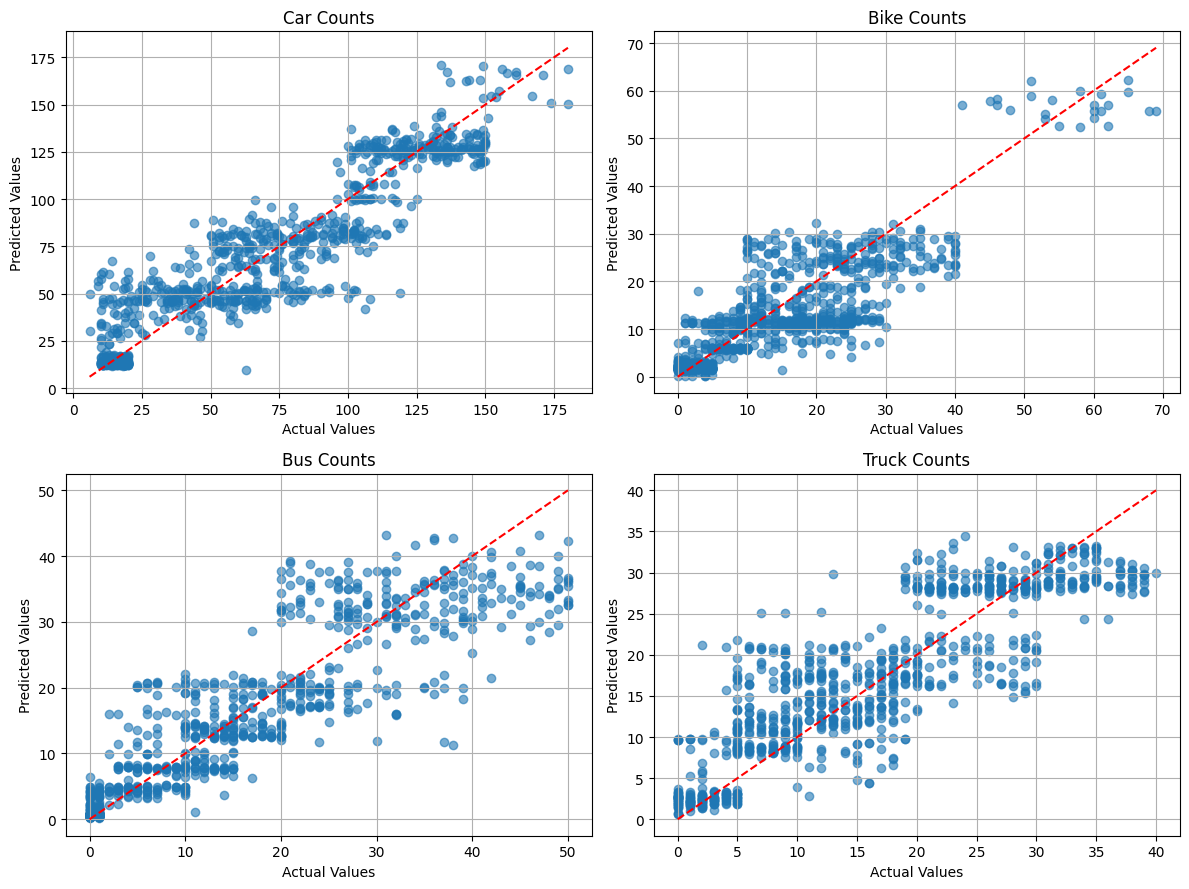

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for i, ax in enumerate(axes.flat):

    ax.scatter(Y_val.iloc[:, i], rf_pred[:, i], alpha=0.6)


    min_val = min(Y_val.iloc[:, i].min(), rf_pred[:, i].min())
    max_val = max(Y_val.iloc[:, i].max(), rf_pred[:, i].max())

    ax.plot([min_val, max_val], [min_val, max_val], 'r--')

    ax.set_title(f"{target_names[i]}")
    ax.set_xlabel("Actual Values")
    ax.set_ylabel("Predicted Values")
    ax.grid(True)

plt.tight_layout()
plt.show()

#### **Results and Discussion**

The overall performance metrics show that both models achieve a similar R² score of approximately 0.77, as well as comparable RMSE and MAE values.

Looking at the individual target variables, the Random Forest model performs better in predicting car, bus, and truck counts, while XGBoost achieves better results for bike counts. However, the differences in MAE and RMSE between the two models are relatively small.

The actual-versus-predicted plots show that both models capture the general traffic patterns reasonably well. However, predicting truck counts appears to be more challenging, as the data points exhibit considerable variability. Overall, both models demonstrate good predictive performance across the four vehicle categories.

## **9. XGBoost vs. Random Forest on Test Set**

In this final evaluation step, we assess both models on the independent test set to determine how well they generalize to unseen data. We compare their overall performance, examine the individual metrics for each target variable, and visualize the actual versus predicted traffic counts. This allows us to evaluate the models' generalization capabilities and identify potential differences between their validation and test performance.

#### **Overall Model Performance: XGBoost vs. Random Forest**

In [31]:
# Generate predictions on the test set for both models
xgb_pred = xgb_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

# Calculate and store evaluation metrics (R², MSE, RMSE, MAE) for both models in a DataFrame
results_test = pd.DataFrame({
    "Model": ["XGBoost", "Random Forest"],
    "R2": [r2_score(Y_test, xgb_pred), r2_score(Y_test, rf_pred)],
    "MSE": [mean_squared_error(Y_test, xgb_pred), mean_squared_error(Y_test, rf_pred)],
    "RMSE": [np.sqrt(mean_squared_error(Y_test, xgb_pred)), np.sqrt(mean_squared_error(Y_test, rf_pred))],
    "MAE": [mean_absolute_error(Y_test, xgb_pred), mean_absolute_error(Y_test, rf_pred)]
})

# Display the validation results rounded to three decimal places
print(results_test.round(3))

           Model     R2      MSE    RMSE    MAE
0        XGBoost  0.780  111.020  10.537  6.557
1  Random Forest  0.773  106.878  10.338  6.600


#### **Metrics per Target: XGBoost vs. Random Forest**

In [32]:
# Calculate and compare R² scores for each target variable

results_per_target_test = []

for i, target in enumerate(target_names):

  results_per_target_test.append({
      "Target": target,
      "XGBoost R2": r2_score(Y_test.iloc[:, i], xgb_pred[:, i]),
      "XGBoost RMSE": np.sqrt(mean_squared_error(Y_test.iloc[:, i], xgb_pred[:, i])),
      "XGBoost MAE": mean_absolute_error(Y_test.iloc[:, i], xgb_pred[:, i]),
      "Random Forest R2": r2_score(Y_test.iloc[:, i], rf_pred[:, i]),
      "Random Forest RMSE": np.sqrt(mean_squared_error(Y_test.iloc[:, i], rf_pred[:, i])),
      "Random Forest MAE": mean_absolute_error(Y_test.iloc[:, i], rf_pred[:, i])
  })

# Store the per-target results in a DataFrame
target_comparison_test = pd.DataFrame(results_per_target_test)

# Display the validation results rounded to three decimal places
print(target_comparison_test.round(3))

         Target  XGBoost R2  XGBoost RMSE  XGBoost MAE  Random Forest R2  \
0    Car Counts       0.843        18.273       13.013             0.853   
1   Bike Counts       0.742         6.279        4.713             0.712   
2    Bus Counts       0.807         6.434        4.457             0.815   
3  Truck Counts       0.729         5.420        4.045             0.711   

   Random Forest RMSE  Random Forest MAE  
0              17.674             12.873  
1               6.638              4.983  
2               6.303              4.347  
3               5.599              4.197  


#### **XGBoost - Actual vs. Predicted on Test Set**

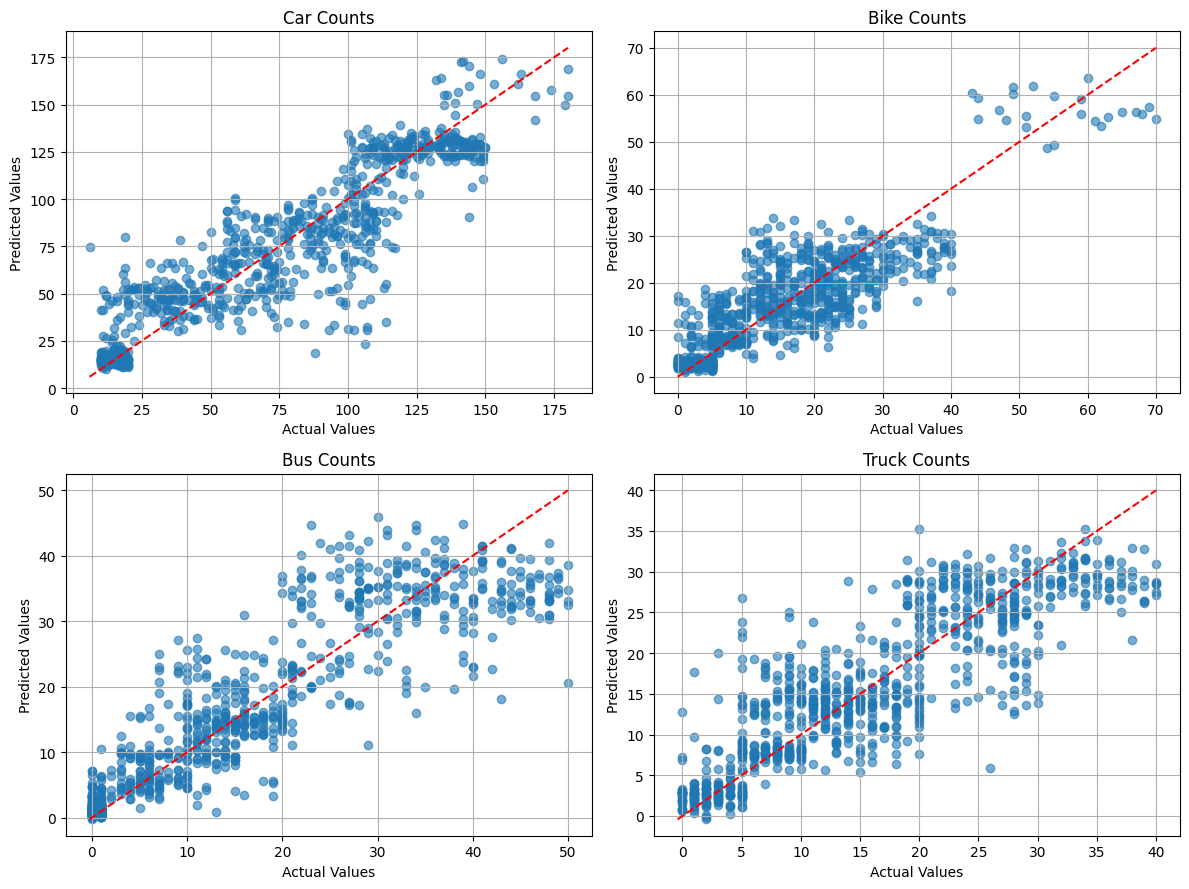

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for i, ax in enumerate(axes.flat):

    ax.scatter(Y_test.iloc[:, i], xgb_pred[:, i], alpha=0.6)


    min_val = min(Y_test.iloc[:, i].min(), xgb_pred[:, i].min())
    max_val = max(Y_test.iloc[:, i].max(), xgb_pred[:, i].max())

    ax.plot([min_val, max_val], [min_val, max_val], 'r--')

    ax.set_title(f"{target_names[i]}")
    ax.set_xlabel("Actual Values")
    ax.set_ylabel("Predicted Values")
    ax.grid(True)

plt.tight_layout()
plt.show()

#### **Random Forest - Actual vs. Predicted on Test Set**

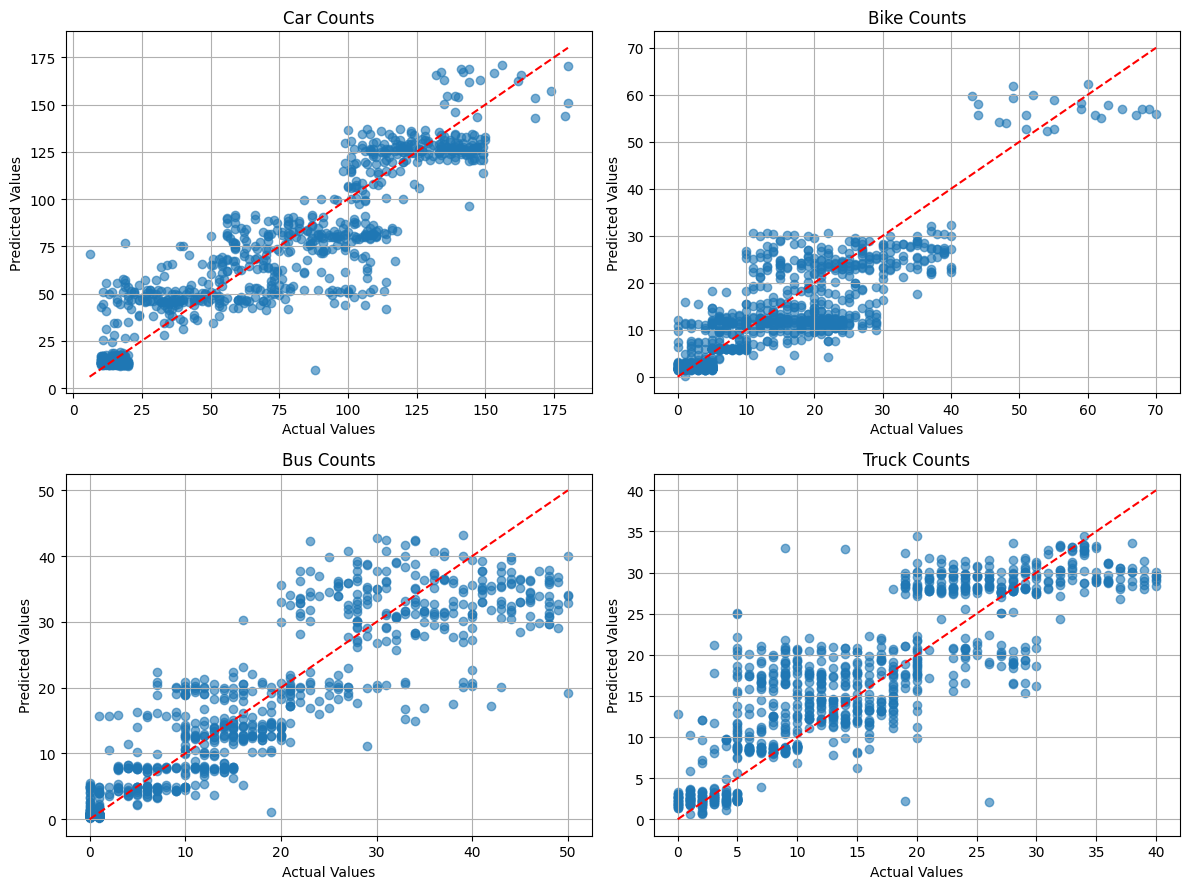

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for i, ax in enumerate(axes.flat):

    ax.scatter(Y_test.iloc[:, i], rf_pred[:, i], alpha=0.6)


    min_val = min(Y_test.iloc[:, i].min(), rf_pred[:, i].min())
    max_val = max(Y_test.iloc[:, i].max(), rf_pred[:, i].max())

    ax.plot([min_val, max_val], [min_val, max_val], 'r--')

    ax.set_title(f"{target_names[i]}")
    ax.set_xlabel("Actual Values")
    ax.set_ylabel("Predicted Values")
    ax.grid(True)

plt.tight_layout()
plt.show()

#### **Results and Discussion**

The overall performance metrics show that both models achieve similar R² scores, as well as comparable RMSE and MAE values. XGBoost performs slightly better overall, achieving an R² score of approximately 0.78.

Looking at the individual target variables, Random Forest performs better when predicting car and bus counts, whereas XGBoost achieves better results for bike and truck counts. Nevertheless, both models show relatively similar RMSE and MAE values across the different traffic categories.

The actual-versus-predicted plots show that both models capture the general traffic patterns reasonably well. As observed in the previous section, predicting truck counts remains more challenging due to the high variability in the data. Despite this, both models demonstrate good overall predictive performance.



## **10. Conclusion**

Both models demonstrate good predictive performance on the test set, with overall R² scores of approximately 0.78. Compared to the validation set, both models achieve slightly better results on the test set.

XGBoost performs particularly well for car, bus, and truck counts, achieving R² scores of 0.843, 0.807, and 0.729, respectively. Random Forest achieves a slightly higher R² score for car and bus counts (0.853 and 0.815), while XGBoost performs considerably better for bike and truck counts.

Overall, both models are capable of capturing the traffic patterns reasonably well. Especially for car and bus counts, both models achieve R² scores above 0.8, indicating a strong predictive performance. Bike and truck counts remain somewhat more challenging to predict, although XGBoost achieves comparatively good results for both categories.